## Extracao dos dados

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
import numpy as np
import seaborn as sns
from scipy import stats
import json
import subprocess
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

dataframe_de_churn_inicial = pd.read_csv("../../../data/raw/Telco-Customer-Churn.csv", sep=",")

dataframe_de_churn_inicial.head(n=100)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Transformacao de nomes de features para portugues

In [58]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_durante_trimestre",
    "Churn": "target",
}

dataframe_de_churn_inicial_colunas_traduzidas = dataframe_de_churn_inicial.rename(columns=colunas_pt_br)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)

,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Mudanca da variavel target para binaria

In [63]:
dataframe_de_churn_inicial_colunas_traduzidas["target"] = dataframe_de_churn_inicial_colunas_traduzidas["target"].replace({"Yes": 1, "No": 0})


df = dataframe_de_churn_inicial_colunas_traduzidas[dataframe_de_churn_inicial_colunas_traduzidas["dependentes"] == "Yes"]

df["target"].value_counts()

target
0    1784
1     326
Name: count, dtype: int64

## Removendo features sensiveis

In [ ]:
colunas_sensiveis_sem_relevancia_para_churn = ["id_cliente", "genero", "dependentes"]

dataframe_de_churn_inicial_colunas_sensiveis_removidas = dataframe_de_churn_inicial_colunas_traduzidas.drop(columns=colunas_sensiveis_sem_relevancia_para_churn)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Binarizando features categoricas deterministicas

In [ ]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas["casado"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["casado"].map({"Yes": 1, "No": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["fatura_sem_papel"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["fatura_sem_papel"].map({"Yes": 1, "No": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_telefonico"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_telefonico"].map({"Yes": 1, "No": 0})

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,1,Electronic check,78.95,927.35,1
96,0,1,71,1,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,1,Credit card (automatic),66.85,4748.7,0
97,0,0,5,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,0,Mailed check,21.05,113.85,1
98,0,0,52,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,0,Bank transfer (automatic),21.00,1107.2,0


## Trabalhando com features binarias nao determinitiscas

In [ ]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_seguranca_online"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_seguranca_online"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_backup_online"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_backup_online"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_protecao_dispositivo"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_protecao_dispositivo"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_suporte_tecnico_premium"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_suporte_tecnico_premium"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_tv_terceiros"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_tv_terceiros"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_filmes_terceiros"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_streaming_filmes_terceiros"].map({"Yes": 1, "No": 0, "No internet service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_multiplas_linhas"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_multiplas_linhas"].map({"Yes": 1, "No": 0, "No phone service": 0})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_de_internet"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["possui_servico_de_internet"].map({"No": 0, "Fiber optic": 1, "DSL": 2})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["tipo_contrato"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["tipo_contrato"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
dataframe_de_churn_inicial_colunas_sensiveis_removidas["metodo_pagamento"] = dataframe_de_churn_inicial_colunas_sensiveis_removidas["metodo_pagamento"].map({"Mailed check": 0, "Electronic check": 1, "Bank transfer (automatic)": 2, "Credit card (automatic)": 3})

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,0,2,0,1,0,0,0,0,0,1,1,29.85,29.85,0
1,0,0,34,1,0,2,1,0,1,0,0,0,1,0,0,56.95,1889.5,0
2,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1
3,0,0,45,0,0,2,1,0,1,1,0,0,1,0,2,42.30,1840.75,0
4,0,0,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,1,0,0,0,0,0,0,1,1,78.95,927.35,1
96,0,1,71,1,1,2,1,1,0,1,0,0,1,1,3,66.85,4748.7,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,0,0,21.05,113.85,1
98,0,0,52,1,0,0,0,0,0,0,0,0,2,0,2,21.00,1107.2,0


## Informacoes estruturais

In [ ]:
dataframe_de_churn_inicial_colunas_sensiveis_removidas.info()
soma_de_registros_iniciais = dataframe_de_churn_inicial_colunas_sensiveis_removidas.shape[0]

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 18 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   cliente_em_idade_avancada          7043 non-null   int64  
 1   casado                             7043 non-null   int64  
 2   meses_como_cliente                 7043 non-null   int64  
 3   possui_servico_telefonico          7043 non-null   int64  
 4   possui_multiplas_linhas            7043 non-null   int64  
 5   possui_servico_de_internet         7043 non-null   int64  
 6   possui_seguranca_online            7043 non-null   int64  
 7   possui_backup_online               7043 non-null   int64  
 8   possui_protecao_dispositivo        7043 non-null   int64  
 9   possui_suporte_tecnico_premium     7043 non-null   int64  
 10  possui_streaming_tv_terceiros      7043 non-null   int64  
 11  possui_streaming_filmes_terceiros  7043 non-null   int64  
 12  tip

## Identificando Missing Values

In [ ]:
print(dataframe_de_churn_inicial_colunas_sensiveis_removidas.isna().sum())
dataframe_validacao_cenario_meses_como_cliente_zero = dataframe_de_churn_inicial_colunas_sensiveis_removidas[
    (dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"].isna())
    | (dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"] == 0)]
dataframe_validacao_cenario_meses_como_cliente_zero.head(n=100)

cliente_em_idade_avancada            0
casado                               0
meses_como_cliente                   0
possui_servico_telefonico            0
possui_multiplas_linhas              0
possui_servico_de_internet           0
possui_seguranca_online              0
possui_backup_online                 0
possui_protecao_dispositivo          0
possui_suporte_tecnico_premium       0
possui_streaming_tv_terceiros        0
possui_streaming_filmes_terceiros    0
tipo_contrato                        0
fatura_sem_papel                     0
metodo_pagamento                     0
cobranca_mensal                      0
total_cobrado_durante_trimestre      0
target                               0
dtype: int64


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
488,0,1,0,0,0,2,1,0,1,1,1,0,2,1,2,52.55,,0
753,0,0,0,1,0,0,0,0,0,0,0,0,2,0,0,20.25,,0
936,0,1,0,1,0,2,1,1,1,0,1,1,2,0,0,80.85,,0
1082,0,1,0,1,1,0,0,0,0,0,0,0,2,0,0,25.75,,0
1340,0,1,0,0,0,2,1,1,1,1,1,0,2,0,3,56.05,,0
3331,0,1,0,1,0,0,0,0,0,0,0,0,2,0,0,19.85,,0
3826,0,1,0,1,1,0,0,0,0,0,0,0,2,0,0,25.35,,0
4380,0,1,0,1,0,0,0,0,0,0,0,0,2,0,0,20.00,,0
5218,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,19.70,,0
6670,0,1,0,1,1,2,0,1,1,1,1,0,2,0,0,73.35,,0


## Removendo os Missing Values

In [ ]:
meses_como_cliente_igual_a_zero = dataframe_de_churn_inicial_colunas_sensiveis_removidas["meses_como_cliente"] == 0
total_cobrado_numerico = pd.to_numeric(dataframe_de_churn_inicial_colunas_sensiveis_removidas["total_cobrado_durante_trimestre"], errors="coerce")
total_cobrado_nulo_vazio_ou_zero = total_cobrado_numerico.isna() | (total_cobrado_numerico == 0)

dataframe_de_churn_missing_values_aplicado = dataframe_de_churn_inicial_colunas_sensiveis_removidas[
    ~(meses_como_cliente_igual_a_zero & total_cobrado_nulo_vazio_ou_zero)
]


soma_de_registros_atuais = dataframe_de_churn_missing_values_aplicado.shape[0]
print(f"Registros iniciais: {soma_de_registros_iniciais}, Registros atuais: {soma_de_registros_atuais}, Registros removidos: {soma_de_registros_iniciais - soma_de_registros_atuais}")
dataframe_de_churn_missing_values_aplicado["total_cobrado_durante_trimestre"] = dataframe_de_churn_missing_values_aplicado["total_cobrado_durante_trimestre"].astype("float64")
dataframe_de_churn_missing_values_aplicado.head(n=100)


Registros iniciais: 7043, Registros atuais: 7032, Registros removidos: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,0,2,0,1,0,0,0,0,0,1,1,29.85,29.85,0
1,0,0,34,1,0,2,1,0,1,0,0,0,1,0,0,56.95,1889.50,0
2,0,0,2,1,0,2,1,1,0,0,0,0,0,1,0,53.85,108.15,1
3,0,0,45,0,0,2,1,0,1,1,0,0,1,0,2,42.30,1840.75,0
4,0,0,2,1,0,1,0,0,0,0,0,0,0,1,1,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,1,0,0,0,0,0,0,1,1,78.95,927.35,1
96,0,1,71,1,1,2,1,1,0,1,0,0,1,1,3,66.85,4748.70,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,0,0,21.05,113.85,1
98,0,0,52,1,0,0,0,0,0,0,0,0,2,0,2,21.00,1107.20,0


## Proporcao da variavel target

=== DISTRIBUICAO DA VARIAVEL TARGET ===

Contagem:
target
0    5163
1    1869
Name: count, dtype: int64

Percentual:
Nao cancelou (0): 73.42%
Cancelou (1): 26.58%


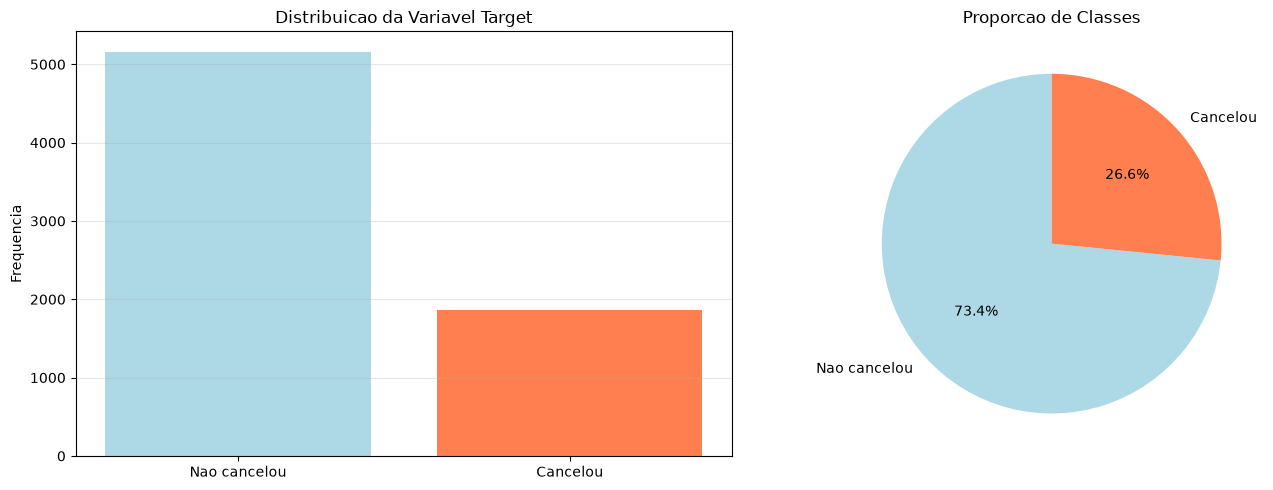


Ratio de balanceamento: 0.36
Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.


In [ ]:
print("=== DISTRIBUICAO DA VARIAVEL TARGET ===\n")
target_counts = dataframe_de_churn_missing_values_aplicado["target"].value_counts()
target_percentages = dataframe_de_churn_missing_values_aplicado["target"].value_counts(normalize=True) * 100

print("Contagem:")
print(target_counts)
print("\nPercentual:")
for idx, pct in target_percentages.items():
    label = "Nao cancelou" if idx == 0 else "Cancelou"
    print(f"{label} ({idx}): {pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['Nao cancelou', 'Cancelou'], target_counts.values, color=['lightblue', 'coral'])
axes[0].set_ylabel('Frequencia')
axes[0].set_title('Distribuicao da Variavel Target')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(target_counts.values, labels=['Nao cancelou', 'Cancelou'],
            autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
axes[1].set_title('Proporcao de Classes')

plt.tight_layout()
plt.show()

ratio = target_counts.min() / target_counts.max()
print(f"\nRatio de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.")
else:
    print("Dataset razoavelmente balanceado.")

## Aplicando class_weigth para balanceamento entre as classes

In [ ]:
classes = np.unique(dataframe_de_churn_missing_values_aplicado["target"])
pesos = compute_class_weight(class_weight="balanced", classes=classes, y=dataframe_de_churn_missing_values_aplicado["target"])

class_weight = dict(zip(classes, pesos))
print("Pesos calculados por classe (para uso no parametro class_weight do modelo):")
print(class_weight)

Pesos calculados por classe (para uso no parametro class_weight do modelo):
{np.int64(0): np.float64(0.6809994189424753), np.int64(1): np.float64(1.8812199036918138)}


## Analise de dispersao das variaveis numericas em relacao a media

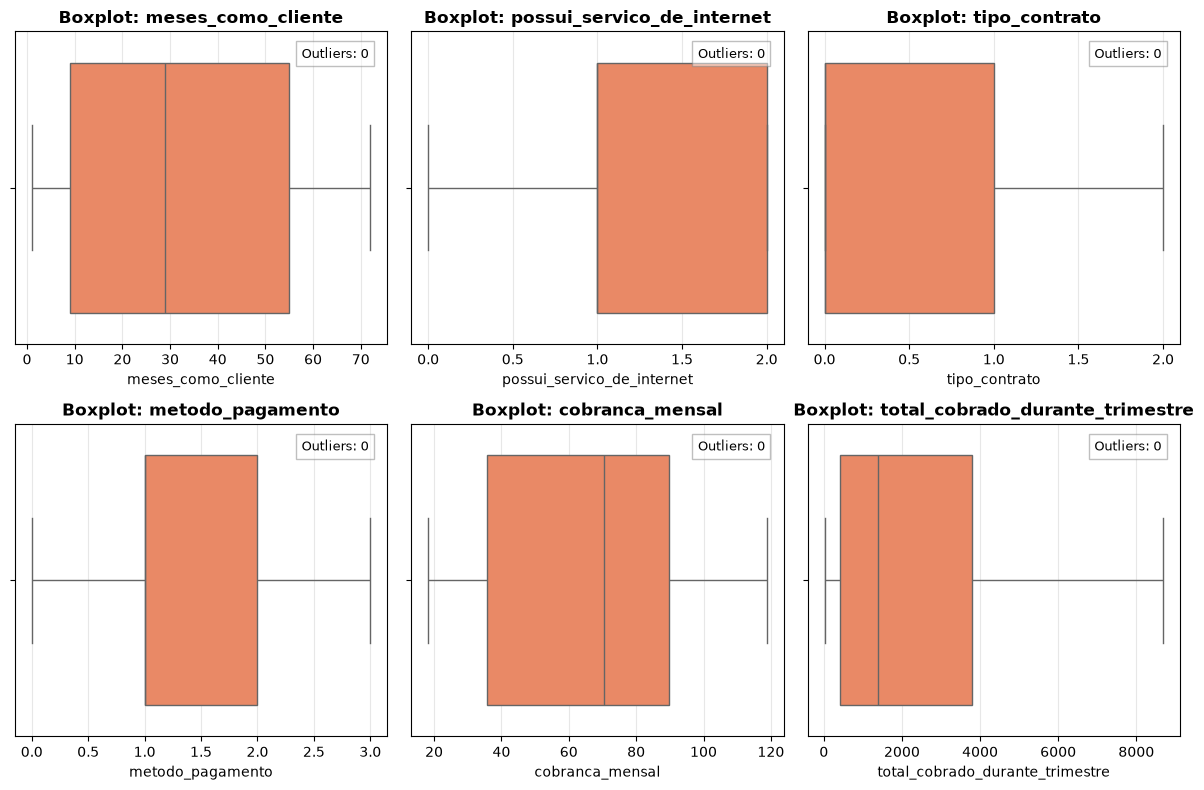

In [ ]:
numeric_cols = ["meses_como_cliente", "possui_servico_de_internet", "tipo_contrato", "metodo_pagamento", "cobranca_mensal", "total_cobrado_durante_trimestre"]

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=dataframe_de_churn_missing_values_aplicado[col], ax=axes[idx], color='coral')
    axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].grid(axis='x', alpha=0.3)

    col_zscore = np.abs(stats.zscore(dataframe_de_churn_missing_values_aplicado[col].dropna()))
    outlier_count = (col_zscore > 3).sum()
    axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                   transform=axes[idx].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

for ax in axes[n:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

## Convertendo a variavel metodo_pagamento para one hot enconding

In [ ]:
codigo_para_metodo_pagamento = {0: "mailed_check", 1: "electronic_check", 2: "bank_transfer_automatic", 3: "credit_card_automatic"}

metodo_pagamento_dummies = pd.get_dummies(
    dataframe_de_churn_missing_values_aplicado["metodo_pagamento"].map(codigo_para_metodo_pagamento),
    prefix="metodo_pagamento"
).astype(int)

dataframe_de_churn_missing_values_aplicado = pd.concat(
    [dataframe_de_churn_missing_values_aplicado.drop(columns=["metodo_pagamento"]), metodo_pagamento_dummies],
    axis=1
)

dataframe_de_churn_missing_values_aplicado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,2,0,1,0,0,0,0,0,1,29.85,29.85,0,0,0,1,0
1,0,0,34,1,0,2,1,0,1,0,0,0,1,0,56.95,1889.50,0,0,0,0,1
2,0,0,2,1,0,2,1,1,0,0,0,0,0,1,53.85,108.15,1,0,0,0,1
3,0,0,45,0,0,2,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,0
4,0,0,2,1,0,1,0,0,0,0,0,0,0,1,70.70,151.65,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,0,1,0
96,0,1,71,1,1,2,1,1,0,1,0,0,1,1,66.85,4748.70,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,1,0,0,0


## Informacoes Estatisticas

In [ ]:
colunas_para_describe = ["meses_como_cliente", "possui_servico_de_internet", "tipo_contrato", "cobranca_mensal", "total_cobrado_durante_trimestre"]

dataframe_de_churn_missing_values_aplicado[colunas_para_describe].describe().round(2)

,meses_como_cliente,possui_servico_de_internet,tipo_contrato,cobranca_mensal,total_cobrado_durante_trimestre
count,7032.00,7032.00,7032.00,7032.00,7032.00
mean,32.42,1.13,0.69,64.80,2283.30
std,24.55,0.74,0.83,30.09,2266.77
min,1.00,0.00,0.00,18.25,18.80
25%,9.00,1.00,0.00,35.59,401.45
50%,29.00,1.00,0.00,70.35,1397.48
75%,55.00,2.00,1.00,89.86,3794.74
max,72.00,2.00,2.00,118.75,8684.80


## Dividindo dados entre treino e teste

In [ ]:
X = dataframe_de_churn_missing_values_aplicado.drop(columns=["target"])
y = dataframe_de_churn_missing_values_aplicado["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (4922, 20), X_test: (2110, 20), y_train: (4922,), y_test: (2110,)


## Redimensionando a escala dos dados antes do treino

In [ ]:
colunas_para_escalonar = ["meses_como_cliente", "possui_servico_de_internet", "tipo_contrato", "cobranca_mensal", "total_cobrado_durante_trimestre"]

escalonador = StandardScaler()

X_train_escalonado = X_train.copy()
X_test_escalonado = X_test.copy()

X_train_escalonado[colunas_para_escalonar] = escalonador.fit_transform(X_train[colunas_para_escalonar])
X_test_escalonado[colunas_para_escalonar] = escalonador.transform(X_test[colunas_para_escalonar])

X_train_escalonado.head(n=100)

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
3946,0,0,-0.952316,0,0,1.183629,1,0,1,1,1,1,-0.834624,0,-0.202600,-0.767315,0,0,0,1
3394,0,0,-0.262207,1,1,1.183629,1,1,0,0,0,0,0.360958,0,-0.101327,-0.306559,0,0,1,0
1635,0,0,-1.195884,1,0,1.183629,0,0,1,0,1,1,0.360958,1,0.177587,-0.908535,0,0,1,0
4088,0,0,-1.033505,1,1,-0.167756,0,0,0,0,0,0,-0.834624,0,0.298782,-0.776092,0,0,1,0
1886,0,1,1.402172,1,0,1.183629,1,0,1,1,0,0,1.556540,1,-0.139512,0.742090,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4570,0,0,-1.033505,1,0,-1.519141,0,0,0,0,0,0,-0.834624,1,-1.515820,-0.948284,0,0,0,1
3798,0,0,0.387307,1,1,-0.167756,0,0,0,1,1,1,-0.834624,1,1.185330,0.861136,0,0,1,0
4385,0,0,-0.465180,1,0,-1.519141,0,0,0,0,0,0,0.360958,1,-1.469335,-0.819112,0,0,0,1
5644,0,1,-1.277073,1,0,-0.167756,0,0,1,0,0,0,-0.834624,0,0.385112,-0.972314,0,0,1,0


## Treinamento do modelo com class_weight e registro de metricas no DVC

Acuracia: 0.7370
Precisao: 0.5033
Recall: 0.8039
F1-score: 0.6191
ROC AUC: 0.8399
Matriz de confusao:
[[1104  445]
 [ 110  451]]


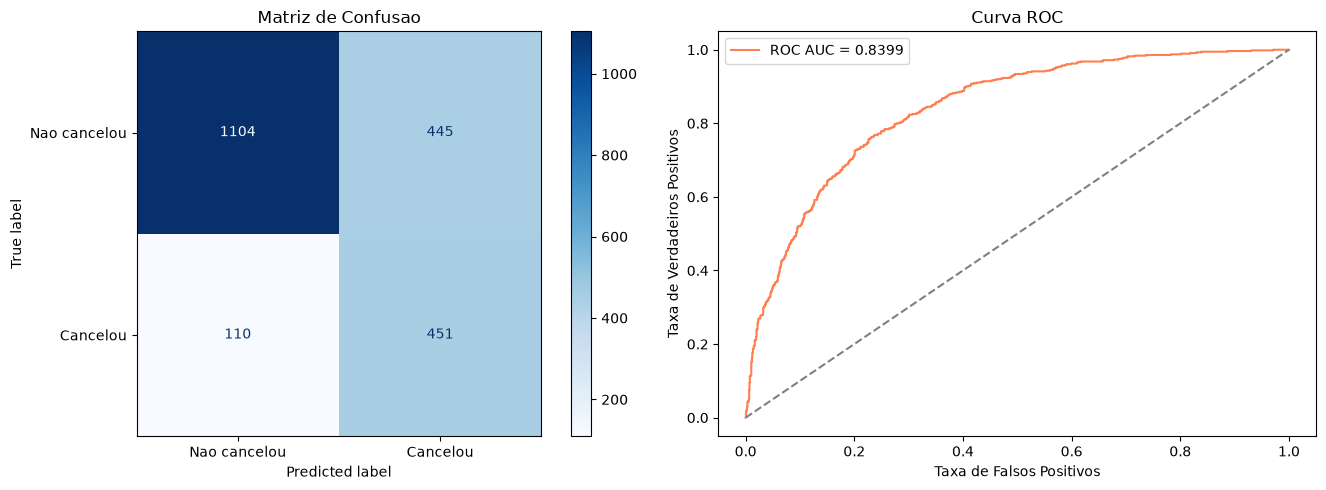

Path                                                          acuracia    f1_score    precisao    recall    roc_auc
notebooks\regressao_logistica\historico\metrics\metrics.json  0.73697     0.61908     0.50335     0.80392   0.83985




In [ ]:
modelo_regressao_logistica = LogisticRegression(class_weight=class_weight, random_state=42, max_iter=1000)
modelo_regressao_logistica.fit(X_train_escalonado, y_train)

y_pred = modelo_regressao_logistica.predict(X_test_escalonado)
y_proba = modelo_regressao_logistica.predict_proba(X_test_escalonado)[:, 1]

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
matriz_confusao = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Acuracia: {acuracia:.4f}")
print(f"Precisao: {precisao:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print("Matriz de confusao:")
print(matriz_confusao)

metricas_dir = Path(r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\notebooks\regressao_logistica\historico\metrics")
metricas_dir.mkdir(parents=True, exist_ok=True)

metricas = {
    "acuracia": acuracia,
    "precisao": precisao,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "matriz_confusao": matriz_confusao.tolist(),
}

with open(metricas_dir / "metrics.json", "w") as arquivo_metricas:
    json.dump(metricas, arquivo_metricas, indent=4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matriz de Confusao")

axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc:.4f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de Falsos Positivos")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
axes[1].set_title("Curva ROC")
axes[1].legend()

plt.tight_layout()
plt.show()

resultado_dvc = subprocess.run(
    ["dvc", "metrics", "show"],
    cwd=r"C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction",
    capture_output=True, text=True
)
print(resultado_dvc.stdout)
print(resultado_dvc.stderr)